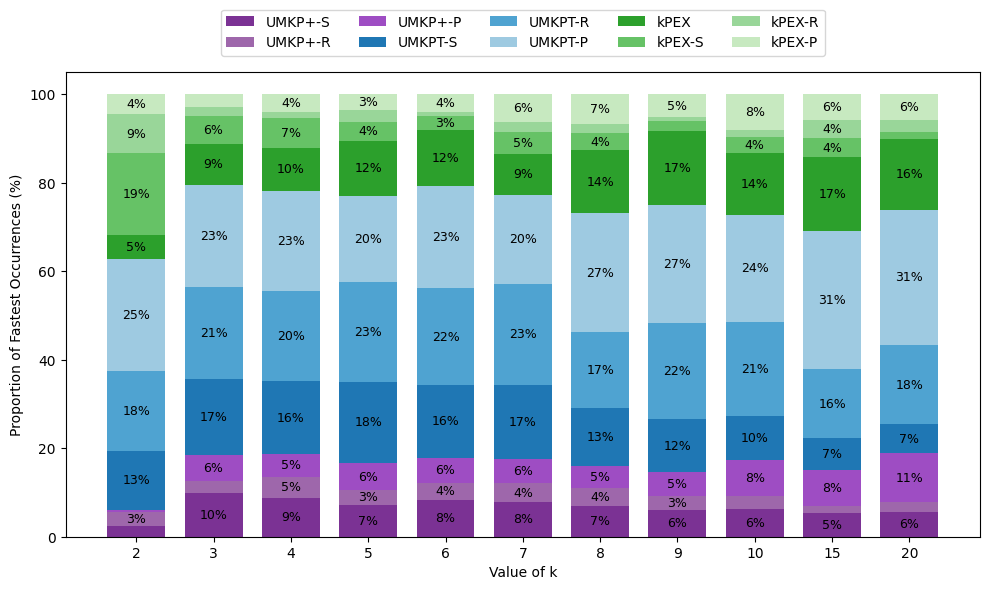

In [10]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

# -------------------------------------------------
# 1. Replace "x" with 1800 in ORIGINAL df (in place)
# -------------------------------------------------

file_path = "results-filtered-dataset.txt"

# Read the first sheet
# df = pd.read_excel(file_path)
df = pd.read_csv(file_path, sep=r"\s+")

# sp_noAltRB = ["UMKP-S", "UMKP-R", "UMKP-P"]
sp_noAltRB = ["UMKP+-S", "UMKP+-R", "UMKP+-P"]
sp_AltRB = ["UMKPT-S", "UMKPT-R", "UMKPT-P"]
dense = ["kPEX", "kPEX-S", "kPEX-R", "kPEX-P"]

# print(df)
sparse = sp_noAltRB + sp_AltRB
all_algos = sparse + dense

df[all_algos] = df[all_algos].replace("x", 1800).apply(pd.to_numeric)


k_values = [2,3,4,5,6,7,8,9,10,15,20]

# store percentages
results = {algo: [] for algo in all_algos}

for k in k_values:

    df_k = df[df["k"] == k]

    if len(df_k) == 0:
        for algo in all_algos:
            results[algo].append(0)
        continue

    winners = df_k[all_algos].idxmin(axis=1)

    win_counts = winners.value_counts()
    total = len(df_k)

    for algo in all_algos:
        wins = win_counts.get(algo, 0)
        percent = (wins / total) * 100
        results[algo].append(percent)

# convert to dataframe for easier plotting
res_df = pd.DataFrame(results, index=k_values)

# ---- plotting ----
colors = {
    # UMKP+ (blue shades)
    "UMKPT-S": "#1f77b4",
    "UMKPT-R": "#4fa3d1",
    "UMKPT-P": "#9ecae1",

    # UMKP (purple shades)
    "UMKP+-S": "#7b3294",
    "UMKP+-R": "#9e67ab",
    "UMKP+-P": "#9e4dc3",

    # kPEX (green shades)
    "kPEX": "#2ca02c",
    "kPEX-S": "#66c266",
    "kPEX-R": "#99d699",
    "kPEX-P": "#c7e9c0"
}
x = np.arange(len(k_values))   # evenly spaced bar positions

fig, ax = plt.subplots(figsize=(10,6))

bottom = np.zeros(len(k_values))
black_font_algos = {"UMKP-S"}
for algo in all_algos:
    vals = res_df[algo].values

    bars = ax.bar(
        x,
        vals,
        bottom=bottom,
        label=algo,
        width=0.75,
        color=colors[algo]
    )

    for i, v in enumerate(vals):
        if v > 3:

            text_color = "white" if algo in black_font_algos else "black"

            ax.text(
                x[i],
                bottom[i] + v/2,
                f"{v:.0f}%",
                ha='center',
                va='center',
                fontsize=9,
                color=text_color
            )

    bottom += vals

ax.set_xlabel("Value of k")
ax.set_ylabel("Proportion of Fastest Occurrences (%)")
# ax.set_title("Algorithm Wins by k")

ax.set_xticks(x)
ax.set_xticklabels(k_values)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=5
)

plt.tight_layout()
# plt.show()